# 03 Majority-Class Baseline
The simplest possible model: always predict the class that is most common in the training seasons. Every other model has to beat this.

### Step 1: imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix)

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})

### Step 2: load and clean `games.csv`
Same cleaning as notebook 02: drop the duplicate games, the games with no stats, and all preseason games.

In [2]:
games = pd.read_csv("../src/dataset/games.csv")

pct = [c for c in games.columns if "PCT" in c]
games[pct] = games[pct].round(3)                       # remove float noise (0.34299999 -> 0.343)
games = games.drop_duplicates("GAME_ID")               # 29 games written twice
games = games[games["PTS_home"].notna()]               # 99 games with no stats and a placeholder label
games = games[games["GAME_ID"] // 10_000_000 != 1]     # preseason games (game id starts with 1)

games["GAME_DATE"] = pd.to_datetime(games["GAME_DATE_EST"])
# 2020 bubble restart: every game at a neutral site, so "home" is only a label
games["NEUTRAL_SITE"] = (games["SEASON"] == 2019) & (games["GAME_DATE"] >= "2020-07-30")
games = games.sort_values(["GAME_DATE", "GAME_ID"]).reset_index(drop=True)

print(len(games), "games")   # should be 24848

24848 games


### Step 3: split by season (never shuffled)
Train on 2003-2016, validate on 2017-2018, test on 2019-2022. The model always learns from the past and is scored on later games.

In [3]:
def season_split(season):
    if season <= 2016:
        return "train"
    if season <= 2018:
        return "validation"
    return "test"

games["SPLIT"] = games["SEASON"].map(season_split)
y = games["HOME_TEAM_WINS"]
is_train, is_val, is_test = (games["SPLIT"] == s for s in ("train", "validation", "test"))

games.groupby("SPLIT", sort=False).agg(games=("HOME_TEAM_WINS", "size"),
                                       home_win_rate=("HOME_TEAM_WINS", "mean")).round(3)

,games,home_win_rate
SPLIT,,
train,18110,0.600
validation,2624,0.589
test,4114,0.554


### Step 4: evaluation (same cell in every model notebook)
Every model gives a probability that the home team wins. We predict "home win" when it is at least 0.5, then report accuracy, precision, recall, F1, ROC-AUC and log loss.

In [4]:
def evaluate(name, y_true, y_prob, threshold=0.5):
    y_prob = np.clip(np.asarray(y_prob, dtype=float), 1e-6, 1 - 1e-6)
    y_pred = (y_prob >= threshold).astype(int)
    return {"model": name,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_prob),
            "log_loss": log_loss(y_true, y_prob, labels=[0, 1])}

def plot_cm(ax, y_true, y_prob, title):
    cm = confusion_matrix(y_true, (np.asarray(y_prob) >= 0.5).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["away win", "home win"], yticklabels=["away win", "home win"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(title)

### Step 5: train the majority-class model
`DummyClassifier` ignores the features. With `strategy="prior"` it always predicts the most common training class (home win) and gives the training home-win rate as its probability, which we need for ROC-AUC and log loss.

In [5]:
from sklearn.dummy import DummyClassifier

X_none = np.zeros((len(games), 1))   # no features needed

majority = DummyClassifier(strategy="prior")
majority.fit(X_none[is_train], y[is_train])

prob_home = majority.predict_proba(X_none)[:, 1]
print("predicted class for every game:", majority.predict(X_none[:1])[0], "(1 = home win)")
print("probability given to a home win:", round(prob_home[0], 4))

predicted class for every game: 1 (1 = home win)
probability given to a home win: 0.5996


### Step 6: evaluate on train, validation and test

In [6]:
results = pd.DataFrame([evaluate(f"majority ({part})", y[mask], prob_home[mask])
                        for part, mask in (("train", is_train), ("validation", is_val), ("test", is_test))])
results.set_index("model").round(4)

,accuracy,precision,recall,f1,roc_auc,log_loss
model,,,,,,
majority (train),0.5996,0.5996,1.0,0.7497,0.5,0.6732
majority (validation),0.5888,0.5888,1.0,0.7412,0.5,0.6775
majority (test),0.5544,0.5544,1.0,0.7134,0.5,0.6914


Why some numbers look odd:
- **Recall = 1.0** because the model calls *every* game a home win, so it never misses one.
- **Precision = accuracy** for the same reason: precision is "of the games we called home wins, how many were", which is every game.
- **F1 looks decent (about 0.71-0.75)** only because recall is 1.0. It does not mean the model is useful.
- **ROC-AUC = 0.5** because every game gets the same probability, so the model cannot rank games at all.

### Step 7: confusion matrices

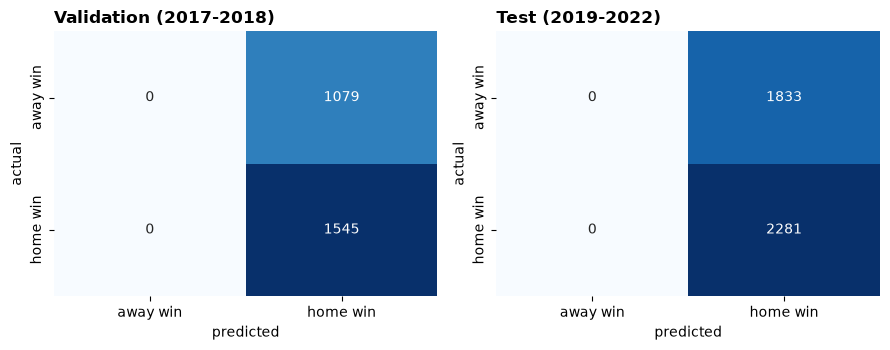

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
plot_cm(axes[0], y[is_val], prob_home[is_val], "Validation (2017-2018)")
plot_cm(axes[1], y[is_test], prob_home[is_test], "Test (2019-2022)")
plt.tight_layout(); plt.show()

### Step 8: why the test score is lower
The majority model's accuracy is just the home win rate, so it moves with the home win rate of each season.

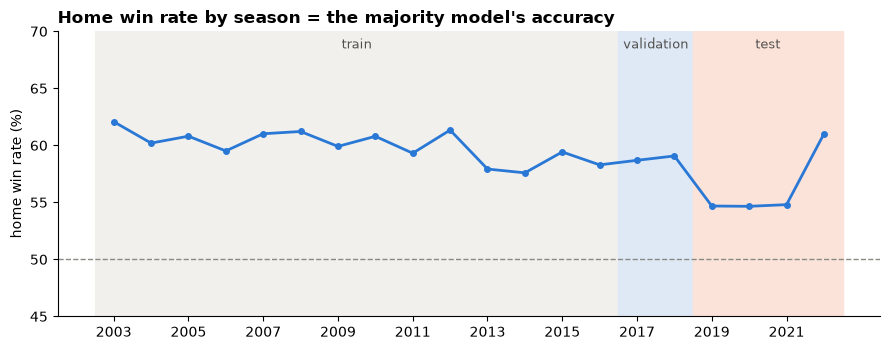

In [8]:
by_season = games.groupby("SEASON")["HOME_TEAM_WINS"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.6))
for part, (lo, hi), shade in (("train", (2002.5, 2016.5), "#f1f0ec"), ("validation", (2016.5, 2018.5), "#dfe9f6"),
                               ("test", (2018.5, 2022.5), "#fbe3d9")):
    ax.axvspan(lo, hi, color=shade, zorder=0)
    ax.text((lo + hi) / 2, 68.5, part, ha="center", fontsize=9, color="#52514e")
ax.plot(by_season.index, by_season.values, color=BLUE, lw=2, marker="o", ms=4)
ax.axhline(50, color=GRAY, ls="--", lw=1)
ax.set_ylim(45, 70); ax.set_xticks(range(2003, 2023, 2)); ax.set_ylabel("home win rate (%)")
ax.set_title("Home win rate by season = the majority model's accuracy")
plt.tight_layout(); plt.show()

### Step 9: observation
Observation: The majority model predicts a home win for every game. It scores 59.96% on train, 58.88% on validation and 55.44% on test, which is exactly the home win rate of each period. Recall is 1.0 and precision equals accuracy because it never predicts an away win, and ROC-AUC is 0.5 because every game gets the same probability (0.5996), so it cannot rank games at all. The test score is lower because the home win rate dropped to about 55% in 2019-2021 (COVID, empty arenas, the bubble), not because the model changed. This is the floor: every real model has to beat 58.88% on validation and 55.44% on test, and a log loss of 0.6775 / 0.6914.